# Task 3 — Group Relative Policy Optimization (GRPO) continuation

**What this notebook does.** (1) validates/fixes the group-advantage defect, (2) runs the required
20-update GRPO continuation from the supplied midpoint (K = 4 completions per prompt, max-length
completions masked), logging reward, KL, within-group reward std, uninformative-group fraction, policy
loss, gradient norm, entropy, length, peak VRAM and wall-clock, (3) the equal-generation group-size study
on the supplied K = 8 cache, (4) canonical GRPO vs Dr.-GRPO length normalisation (matched 8-update forks),
and (5) qualitative examples.

| Item | Setting (`configs/grpo.yaml`) |
|---|---|
| Policy | Qwen2.5-1.5B-Instruct + supplied GRPO LoRA; reference = LoRA disabled; no critic |
| Reward | same frozen RM as PPO (raw score, no EOS penalty) |
| Rollouts | 1 prompt/update × K = 4 samples, T = 0.7, top-p 0.9, ≤ 512 new tokens; truncated completions masked from the loss |
| Loss | clipped ratio objective with group-relative advantage, ε = 0.2, k3 KL penalty β = 0.1, 1 policy epoch, lr 5e-6, grad-clip 1.0 |
| Normalisation | canonical: Σ_t(·)/T_k per sequence then mean; Dr.-GRPO: Σ_t(·)/L_max (L_max = 512) |
| Held-out protocol | identical to Task 2 (same prompts, T = 0.7, ≤ 768 new tokens, seed 6304) |

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from common.analysis import setup_style, savefig, jl, js, excerpt, show_log_tail, grep_log, PALETTE
from common.data import load_yaml, read_jsonl, repo_path
from common.orchestration import run_module, set_log_file
setup_style()
print("repo root:", ROOT)
cfg = load_yaml("configs/grpo.yaml")
R = Path(cfg["results_dir"])
set_log_file("results/logs/t3_notebook.log")

repo root: /workspace/pa2


## 1. Validating the GRPO advantage (deliberate starter defect)
$A_k = (r_k-\mu_r)/(\sigma_r+\varepsilon)$ where μ and σ are computed **over the K completions of the same
prompt**. The starter ignored `group_ids` and normalised over the whole batch, so with several prompts per
batch an easy prompt's completions would all receive positive advantages and a hard prompt's all negative
ones — the update would learn "which prompt was easy" rather than "which answer was better". The fix
normalises inside each group. Tests also confirm the exact per-sequence decomposition used to fit the
loss in 8 GB of VRAM equals the batch loss of the supplied `grpo_policy_loss` for both normalisations.

In [2]:
import inspect, task3_grpo.grpo as grpo_mod
src = inspect.getsource(grpo_mod.group_relative_advantages)
print(src[src.index("# FIX"):])
from scripts.smoke_tests import test_grpo, RESULTS
test_grpo()
assert all(ok for _, ok, _ in RESULTS)

# FIX (deliberate starter defect): the starter normalised with the mean/std of the
    # whole batch, ignoring `group_ids`. GRPO's baseline is the mean of the K completions
    # sampled for the SAME prompt, so each reward must be compared only with its own group.
    # With a batch-wide baseline, an easy prompt's completions all get positive advantages
    # and a hard prompt's all get negative ones, i.e. prompt difficulty leaks into the signal.
    rewards = rewards.float()
    group_ids = torch.as_tensor(group_ids, device=rewards.device)
    adv = torch.zeros_like(rewards)
    for g in torch.unique(group_ids):
        sel = group_ids == g
        r = rewards[sel]
        mean = r.mean()
        std = r.std(unbiased=False).clamp_min(eps)
        adv[sel] = (r - mean) / std
    return adv

[PASS] GRPO advantages are zero-mean within every prompt group 
[PASS] Uninformative (zero-std) group gets zero advantage 
[PASS] GRPO advantage = (r - mu_group)/(sigma_group + eps) 
[PASS] Starter 

In [3]:
display(pd.Series(js("checkpoints/grpo_midpoint_metadata.json")).to_frame("supplied GRPO midpoint (staff training metadata)"))

,supplied GRPO midpoint (staff training metadata)
mean_clipped_ratio,0.2450
mean_completion_length,254.1650
mean_reward,1.3794
mean_reward_std,0.6872
mean_frac_reward_zero_std,0.0200
mean_kl,0.0006
max_completion_length,512.0000
steps,50.0000
num_generations,4.0000
seed,6304.0000


## 2. Standard GRPO continuation (20 updates)

In [4]:
run_module("task3_grpo.continue_train", "--config", "configs/grpo.yaml", "--run-name", "standard",
           skip_if_exists="outputs/task3_grpo/standard/adapter_model.safetensors")
grep_log("results/logs/t3.log", "[standard] update")
summ = js(R / "train_summary_standard.json")
display(pd.DataFrame({"wall-clock (min)": [summ["wall_clock_s"] / 60], "wall-clock excl. thermal pauses (min)": [summ["wall_clock_excluding_thermal_pauses_s"] / 60],
                      "peak VRAM allocated (GiB)": [summ["peak_vram"]["allocated_gib"]], "peak VRAM reserved (GiB)": [summ["peak_vram"]["reserved_gib"]],
                      "generated tokens": [summ["generated_tokens_total"]], "uninformative group fraction": [summ["uninformative_group_fraction"]]},
                     index=["standard GRPO (20 updates)"]).T)

[skip] task3_grpo.continue_train --config configs/grpo.yaml --run-name standard  (found outputs/task3_grpo/standard/adapter_model.safetensors)


[standard] update 1/20 R=1.381 std=0.612 KL=0.0002 H=1.267 L=512 trunc=3 loss=-0.3297 gn=0.112 t=13s
[standard] update 2/20 R=0.707 std=1.205 KL=0.0000 H=0.726 L=512 trunc=4 loss=0.0000 gn=0.000 t=12s
[standard] update 3/20 R=2.740 std=0.000 KL=-0.0010 H=0.111 L=22 trunc=0 loss=0.0000 gn=0.004 t=1s
[standard] update 4/20 R=1.673 std=0.437 KL=0.0001 H=0.716 L=486 trunc=2 loss=-0.3623 gn=0.081 t=12s
[standard] update 5/20 R=1.318 std=0.572 KL=-0.0011 H=1.100 L=8 trunc=0 loss=0.0000 gn=2.320 t=1s
[standard] update 6/20 R=0.047 std=1.073 KL=-0.0007 H=1.427 L=24 trunc=0 loss=0.0000 gn=0.901 t=2s
[standard] update 7/20 R=2.674 std=0.618 KL=0.0004 H=0.815 L=284 trunc=0 loss=0.0000 gn=0.204 t=8s
[standard] update 8/20 R=0.902 std=0.690 KL=0.0002 H=1.193 L=87 trunc=0 loss=0.0000 gn=0.474 t=4s
[standard] update 9/20 R=1.964 std=0.615 KL=0.0000 H=1.498 L=431 trunc=1 loss=-0.4097 gn=0.096 t=12s
[standard] update 10/20 R=2.520 std=0.987 KL=0.0002 H=1.177 L=493 trunc=2 loss=-0.3549 gn=0.104 t=12s
[s

,standard GRPO (20 updates)
wall-clock (min),2.5247
wall-clock excl. thermal pauses (min),2.5247
peak VRAM allocated (GiB),5.2120
peak VRAM reserved (GiB),5.5332
generated tokens,20806.0000
uninformative group fraction,0.1500


saved figure: report/figures/t3_standard_trajectories.pdf


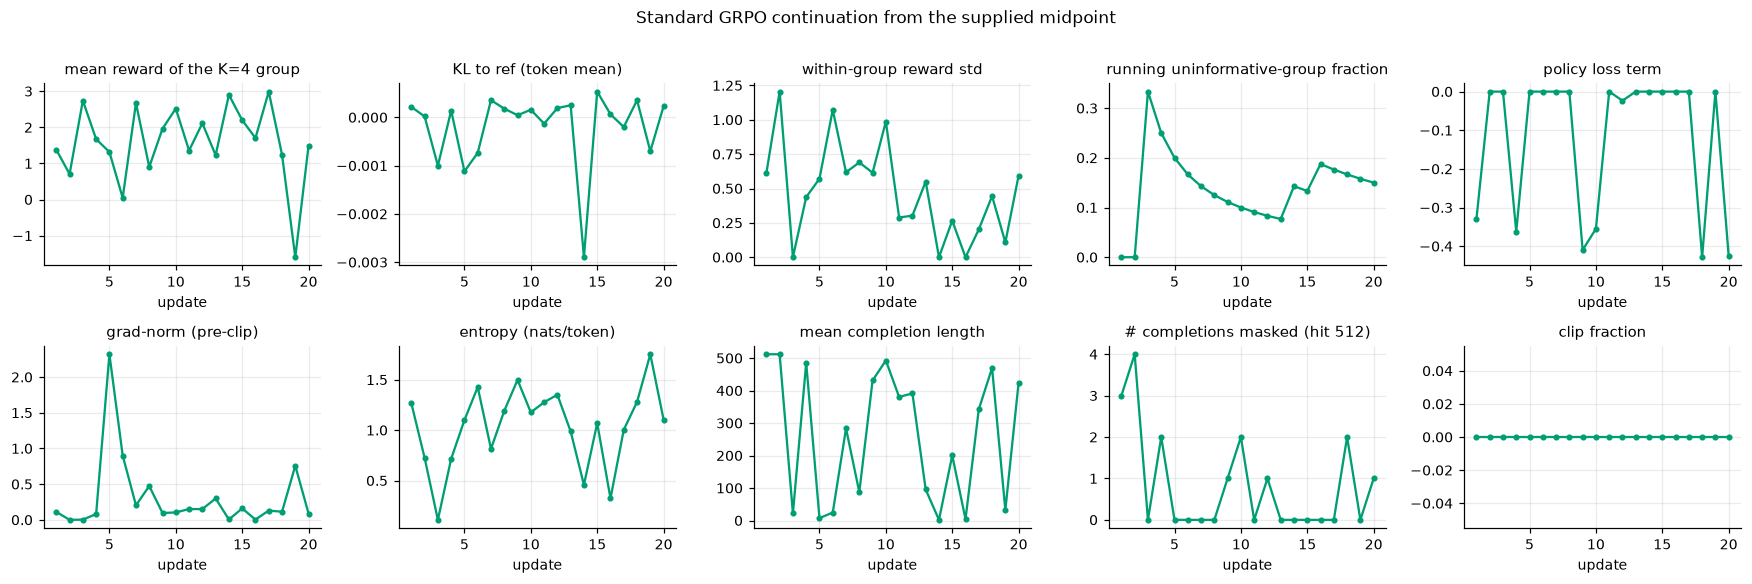

,update,reward,reward_group_std,uninformative_group_fraction,kl_token,kl_k3_loss,policy_loss,grad_norm,entropy,response_length,n_truncated_masked,advantage_abs_mean
0,1,1.3807,0.6117,0.0,0.0002,0.0,-0.3297,0.1118,1.2673,512.00,3,0.8423
1,2,0.7067,1.2051,0.0,0.0000,0.0,0.0000,0.0000,0.7260,512.00,4,0.9824
2,3,2.7402,0.0000,1.0,-0.0010,0.0,0.0000,0.0035,0.1110,22.00,0,0.0000
3,4,1.6733,0.4373,0.0,0.0001,0.0,-0.3623,0.0811,0.7162,485.50,2,0.7285
4,5,1.3179,0.5715,0.0,-0.0011,0.0,-0.0000,2.3198,1.0998,7.50,0,0.7424
5,6,0.0472,1.0726,0.0,-0.0007,0.0,-0.0000,0.9013,1.4267,24.50,0,0.9616
6,7,2.6738,0.6182,0.0,0.0004,0.0,0.0000,0.2039,0.8149,283.50,0,0.8467
7,8,0.9020,0.6897,0.0,0.0002,0.0,-0.0000,0.4740,1.1926,87.25,0,0.9725
8,9,1.9641,0.6151,0.0,0.0000,0.0,-0.4097,0.0964,1.4978,431.25,1,0.8194
9,10,2.5199,0.9874,0.0,0.0002,0.0,-0.3549,0.1040,1.1765,492.75,2,0.8441


completions entering the loss: 64/80 (80.0%); updates with zero policy gradient because all 4 completions were masked: 1


In [5]:
log = jl(R / "train_log_standard.jsonl")
seqs = jl(R / "train_sequences_standard.jsonl")
panels = [("reward", "mean reward of the K=4 group"), ("kl_token", "KL to ref (token mean)"), ("reward_group_std", "within-group reward std"),
          ("running_uninformative_fraction", "running uninformative-group fraction"), ("policy_loss", "policy loss term"),
          ("grad_norm", "grad-norm (pre-clip)"), ("entropy", "entropy (nats/token)"), ("response_length", "mean completion length"),
          ("n_truncated_masked", "# completions masked (hit 512)"), ("clip_fraction", "clip fraction")]
fig, axes = plt.subplots(2, 5, figsize=(16, 5.2))
for ax, (c, t) in zip(axes.flat, panels):
    ax.plot(log["update"], log[c], "o-", ms=3, color=PALETTE[2])
    ax.set_title(t); ax.set_xlabel("update")
fig.suptitle("Standard GRPO continuation from the supplied midpoint", y=1.01)
fig.tight_layout(); savefig(fig, "t3_standard_trajectories"); plt.show()
display(log[["update", "reward", "reward_group_std", "uninformative_group_fraction", "kl_token", "kl_k3_loss", "policy_loss", "grad_norm", "entropy",
             "response_length", "n_truncated_masked", "advantage_abs_mean"]].round(4))
print(f"completions entering the loss: {(~seqs.masked).sum()}/{len(seqs)} ({(~seqs.masked).mean():.1%}); "
      f"updates with zero policy gradient because all 4 completions were masked: {(seqs.groupby('update').masked.all()).sum()}")

In [6]:
run_module("task3_grpo.evaluate", "--config", "configs/grpo.yaml", "--adapter", "outputs/task3_grpo/standard", "--name", "standard",
           skip_if_exists="results/task3_grpo/heldout_standard.json")
run_module("task3_grpo.evaluate", "--config", "configs/grpo.yaml", "--adapter", cfg["paths"]["grpo_midpoint_policy"], "--name", "midpoint",
           skip_if_exists="results/task3_grpo/heldout_midpoint.json")
def hrow(path, name):
    s = js(path)
    return {"policy": name, "RM reward": s["reward_mean"], "KL token-mean": s["kl_token_mean"], "KL per-seq": s["kl_seq_mean"],
            "entropy": s["entropy_token_mean"], "len mean": s["length"]["mean"], "len std": s["length"]["std"], "len IQR": s["length"]["iqr"],
            "truncation rate (768)": s["truncation_rate"], "n prompts": s["n_prompts"]}
rows = [hrow("results/task2_ppo/heldout_sft.json", "SFT (from Task 2 protocol)")] if Path("results/task2_ppo/heldout_sft.json").exists() else []
rows += [hrow(R / "heldout_midpoint.json", "GRPO midpoint"), hrow(R / "heldout_standard.json", "GRPO standard (20 updates)")]
held = pd.DataFrame(rows).set_index("policy"); display(held)

[skip] task3_grpo.evaluate --config configs/grpo.yaml --adapter outputs/task3_grpo/standard --name standard  (found results/task3_grpo/heldout_standard.json)


[skip] task3_grpo.evaluate --config configs/grpo.yaml --adapter checkpoints/grpo_midpoint_policy --name midpoint  (found results/task3_grpo/heldout_midpoint.json)


,RM reward,KL token-mean,KL per-seq,entropy,len mean,len std,len IQR,truncation rate (768),n prompts
policy,,,,,,,,,
SFT (from Task 2 protocol),1.9050,0.0000e+00,0.0000,0.9769,309.5030,262.6667,482.0,0.0788,165
GRPO midpoint,1.8933,-1.8969e-06,-0.0006,0.9691,305.4485,260.7671,448.0,0.0848,165
GRPO standard (20 updates),1.8808,1.1372e-04,0.0352,0.9892,309.8121,263.7759,472.0,0.1030,165


## 3. Equal-generation group-size study (K ∈ {2, 4, 8}) — no training
The cache holds 8 completions with RM rewards for each of 24 held-out prompts (192 generations).
**Partition rule:** each prompt's 8 completions (in `generation_index` order) are split into 8/K disjoint
groups, so every K uses the same 192 generations (K=8 → 24 groups, K=4 → 48, K=2 → 96).
**Difficulty bins (defined once):** a prompt's difficulty is the mean reward of its 8 cached completions;
tertiles → hard / medium / easy (8 prompts each). Because RM rewards are continuous, exact zero-std groups
are rare, so we also report (i) a "weak-signal" fraction (σ < 0.25 reward units) and (ii) the same
analysis with a **binary** reward 1[r > median] to show the low-resolution regime the manual warns about.
A partition-free check averages over *all* C(8, K) subsets.

In [7]:
run_module("task3_grpo.analyze_group_size", "--config", "configs/grpo.yaml", skip_if_exists="results/task3_grpo/group_size_table.csv")
gt, gb, gbin = pd.read_csv(R / "group_size_table.csv"), pd.read_csv(R / "group_size_by_difficulty.csv"), pd.read_csv(R / "group_size_binary_reward.csv")
display(Markdown("**Continuous learned reward**")); display(gt.set_index("K").T.round(4))
display(Markdown("**Binary reward 1[r > median]**")); display(gbin.set_index("K").T.round(4))
display(Markdown("**By prompt difficulty**")); display(gb.pivot_table(index=["reward", "difficulty"], columns="K",
        values=["informative_group_rate", "mean_within_group_std", "relative_signal_variance", "normalized_advantage_variance"]).round(4))

[skip] task3_grpo.analyze_group_size --config configs/grpo.yaml  (found results/task3_grpo/group_size_table.csv)


**Continuous learned reward**

K,2,4,8
n_groups,96.0000,48.0000,24.0000
n_generations,192.0000,192.0000,192.0000
informative_group_rate,0.9375,0.9583,0.9583
uninformative_group_fraction,0.0625,0.0417,0.0417
weak_signal_group_fraction,0.5104,0.2500,0.1250
mean_within_group_std,0.3846,0.5410,0.6191
relative_signal_variance,0.3368,0.4677,0.5599
normalized_advantage_variance,0.9375,0.9583,0.9583
frac_completions_nonzero_advantage,0.9375,0.9583,0.9583
mean_abs_advantage,0.9375,0.8307,0.7939


**Binary reward 1[r > median]**

K,2,4,8
reward,binary: 1[r > median=2.133],binary: 1[r > median=2.133],binary: 1[r > median=2.133]
n_groups,96,48,24
n_generations,192,192,192
informative_group_rate,0.1875,0.3542,0.4583
uninformative_group_fraction,0.8125,0.6458,0.5417
weak_signal_group_fraction,NaN,NaN,NaN
mean_within_group_std,0.0938,0.1631,0.1913
relative_signal_variance,0.0469,0.0755,0.082
normalized_advantage_variance,0.1875,0.3542,0.4583
frac_completions_nonzero_advantage,0.1875,0.3542,0.4583


**By prompt difficulty**

informative_group_rate                mean_within_group_std                 normalized_advantage_variance                relative_signal_variance                
K                                          2       4      8                     2       4       8                             2       4      8                        2       4       8
reward     difficulty                                                                                                                                                                  
binary     easy                       0.1250  0.2500  0.375                0.0625  0.1166  0.1560                        0.1250  0.2500  0.375                   0.0312  0.0547  0.0664
           hard                       0.0000  0.0000  0.000                0.0000  0.0000  0.0000                        0.0000  0.0000  0.000                   0.0000  0.0000  0.0000
           medium                     0.4375  0.8125  1.000                0.2188  0.3728  0.4178                        0.4375  0.8125  1.000                   0.1094  0.1719  0.1797
continuous easy                       1.0000  1.0000  1.000                0.2479  0.4098  0.4948                        1.0000  1.0000  1.000                   0.1080  0.2149  0.3459
           hard                       0.8438  0.8750  0.875                0.4934  0.6615  0.7634                        0.8438  0.8750  0.875                   0.5984  0.7865  0.8869
           medium                     0.9688  1.0000  1.000                0.4124  0.5517  0.5990                        0.9688  1.0000  1.000                   0.3041  0.4017  0.4469

saved figure: report/figures/t3_group_size.pdf


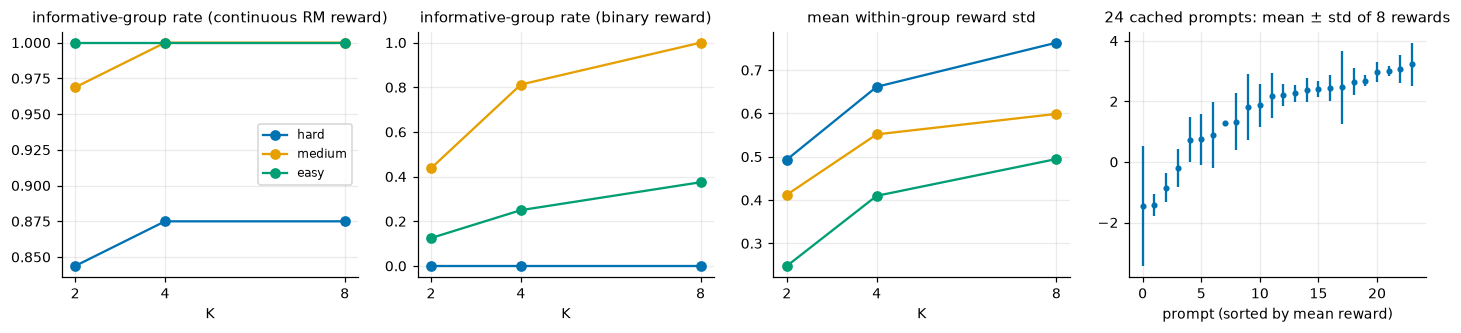

,source_index,mean_reward_8,difficulty,reward_std_8,n_clipped
1,671,-1.456,hard,1.980,2
23,495,-1.420,hard,0.360,0
21,457,-0.852,hard,0.471,0
11,961,-0.194,hard,0.633,0
6,953,0.734,hard,0.747,0
4,175,0.742,hard,0.835,7
13,936,0.894,hard,1.081,0
12,280,1.273,hard,0.000,0
14,254,1.332,medium,0.953,6
8,796,1.817,medium,1.077,3


In [8]:
ps = pd.DataFrame(js(R / "group_size_prompt_stats.json")["prompts"]).sort_values("mean_reward_8")
fig, axes = plt.subplots(1, 4, figsize=(16, 2.9))
for i, (rw, lab) in enumerate([("continuous", "continuous RM reward"), ("binary", "binary reward")]):
    sub = gb[gb.reward == rw]
    for j, dname in enumerate(["hard", "medium", "easy"]):
        d = sub[sub.difficulty == dname]
        axes[i].plot(d.K, d.informative_group_rate, "o-", label=dname, color=PALETTE[j])
    axes[i].set_title(f"informative-group rate ({lab})"); axes[i].set_xlabel("K"); axes[i].set_xticks([2, 4, 8])
axes[0].legend()
for j, dname in enumerate(["hard", "medium", "easy"]):
    d = gb[(gb.reward == "continuous") & (gb.difficulty == dname)]
    axes[2].plot(d.K, d.mean_within_group_std, "o-", label=dname, color=PALETTE[j])
axes[2].set_title("mean within-group reward std"); axes[2].set_xlabel("K"); axes[2].set_xticks([2, 4, 8])
axes[3].errorbar(range(len(ps)), ps.mean_reward_8, yerr=ps.reward_std_8, fmt="o", ms=3, color=PALETTE[0])
axes[3].set_title("24 cached prompts: mean ± std of 8 rewards"); axes[3].set_xlabel("prompt (sorted by mean reward)")
savefig(fig, "t3_group_size"); plt.show()
display(ps.round(3))

## 4. Canonical GRPO vs Dr.-GRPO normalisation (matched 8-update forks)
Both forks start from the same midpoint with identical prompts, sampling seeds, K, ε, β, reward and
512-token cap; only the per-sequence normaliser changes (1/T_k vs 1/L_max). For every completion that
enters the loss we log its length, advantage, the per-token loss weight |A|/(B·denominator) and the L2 norm of
the gradient it contributes (measured by differencing accumulated LoRA gradients).

In [9]:
run_module("task3_grpo.compare_normalization", "--config", "configs/grpo.yaml")
nt = pd.read_csv(R / "normalization_table.csv").set_index("fork")
display(nt.T)

[run] python -m task3_grpo.compare_normalization --config configs/grpo.yaml


Fork updates: 8


Compare loss_type='grpo' vs loss_type='dr_grpo' from the identical supplied midpoint.


[skip] task3_grpo.evaluate --config configs/grpo.yaml --adapter checkpoints/grpo_midpoint_policy --name midpoint  (found results/task3_grpo/heldout_midpoint.json)


[skip] task3_grpo.continue_train --config configs/grpo.yaml --output outputs/task3_grpo/fork_grpo --updates 8 --loss-type grpo --run-name fork_grpo  (found outputs/task3_grpo/fork_grpo/adapter_model.safetensors)


...

sequence_weight_short_mean             0.142      0.003923                   NaN


sequence_weight_long_mean           0.229789       0.08715                   NaN


mean_length_pos_adv                    192.3    115.333333                   NaN


mean_length_neg_adv               119.888889        118.25                   NaN


fork,fork_grpo,fork_dr_grpo,midpoint
loss_type,grpo,dr_grpo,midpoint (no update)
heldout_reward,1.8554,1.9162,1.8933
heldout_kl_token,0.0001,0.0001,-0.0
heldout_kl_seq,0.0276,0.0242,-0.0006
heldout_entropy,0.9839,0.9731,0.9691
heldout_len_mean,308.7333,308.6303,305.4485
heldout_len_std,266.7777,261.3363,260.7671
heldout_len_iqr,447.0,452.0,448.0
heldout_truncation_rate,0.1212,0.0848,0.0848
train_reward_mean,1.4371,1.0646,NaN


saved figure: report/figures/t3_normalization.pdf


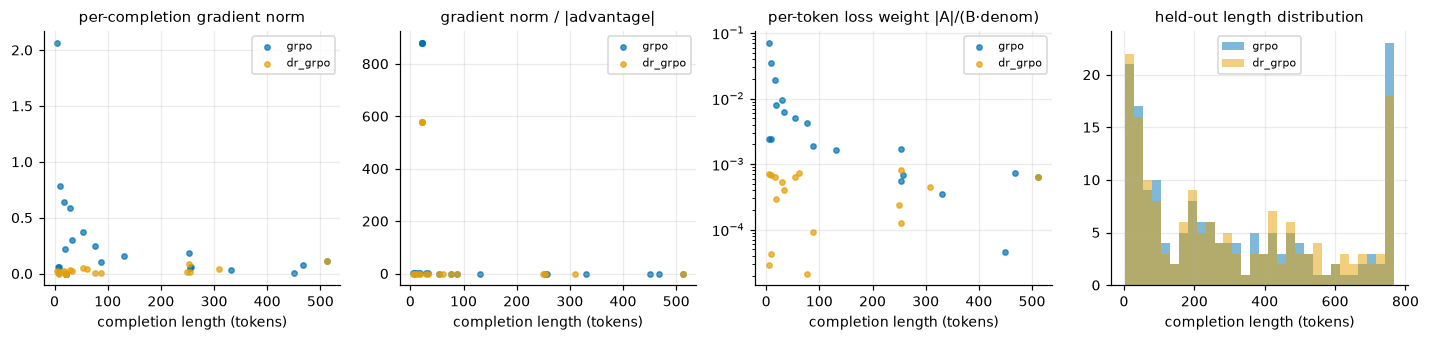

grpo per-update mean length: [512.0, 512.0, 22.0, 486.0, 8.0, 24.0, 274.0, 87.0]
dr_grpo per-update mean length: [512.0, 512.0, 22.0, 512.0, 8.0, 24.0, 266.0, 70.0]


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for i, lt in enumerate(["grpo", "dr_grpo"]):
    s = jl(R / f"train_sequences_fork_{lt}.jsonl"); s = s[~s.masked]
    axes[0].scatter(s.length, s.grad_norm, s=12, alpha=0.7, label=lt, color=PALETTE[i])
    axes[1].scatter(s.length, s.grad_norm / s.advantage.abs().clip(lower=1e-6), s=12, alpha=0.7, label=lt, color=PALETTE[i])
    axes[2].scatter(s.length, s.token_weight, s=12, alpha=0.7, label=lt, color=PALETTE[i])
    h = jl(R / f"heldout_fork_{lt}.jsonl")
    axes[3].hist(h.response_tokens, bins=30, alpha=0.5, label=lt, color=PALETTE[i])
for ax, t in zip(axes, ["per-completion gradient norm", "gradient norm / |advantage|", "per-token loss weight |A|/(B·denom)", "held-out length distribution"]):
    ax.set_title(t); ax.set_xlabel("completion length (tokens)"); ax.legend(fontsize=7)
axes[2].set_yscale("log")
savefig(fig, "t3_normalization"); plt.show()
for lt in ["grpo", "dr_grpo"]:
    d = jl(R / f"train_log_fork_{lt}.jsonl")
    print(lt, "per-update mean length:", d.response_length.round(0).tolist())

## 5. Qualitative evidence
(a) The most and least informative groups in the standard run; (b) a long vs a short completion from the
same group under the two normalisations.

In [11]:
by = seqs.groupby("update")
stds = by.reward.std(ddof=0)
prompts = {p["update"]: p for p in js(R / "train_prompts_standard.json")}
from common.data import prompt_messages
pool = {str(r["source_index"]): r for r in read_jsonl(cfg["paths"]["rl_prompt_train"])}
for label, u in [("most informative group", stds.idxmax()), ("least informative group", stds.idxmin())]:
    p = pool[prompts[u - 1]["source_index"]]
    g = seqs[seqs["update"] == u]
    print(f"=== {label}: update {u}, reward std {stds[u]:.3f}\nPROMPT: {excerpt(prompt_messages(p)[-1]['content'], 200)}")
    display(g[["i", "reward", "advantage", "length", "truncated", "masked", "grad_norm"]].round(3))

=== most informative group: update 2, reward std 1.205
PROMPT: How to write cross-platform GUI app in Python for Android, Windows, Linux, iOS


,i,reward,advantage,length,truncated,masked,grad_norm
4,0,1.863,0.960,512,True,True,0.0
5,1,-0.160,-0.719,512,True,True,0.0
6,2,-0.794,-1.246,512,True,True,0.0
7,3,1.918,1.005,512,True,True,0.0


=== least informative group: update 3, reward std 0.000
PROMPT: Detailed Instructions: In this task, you are given a country name, and you need to return the year i [...] ola
Solution: 1975 Explanation: 1975 is the year of independence of Angola. Problem: Gabon Solution:


,i,reward,advantage,length,truncated,masked,grad_norm
8,0,2.74,0.0,22,False,False,0.001
9,1,2.74,0.0,22,False,False,0.001
10,2,2.74,0.0,22,False,False,0.001
11,3,2.74,0.0,22,False,False,0.001


In [12]:
for lt in ["grpo", "dr_grpo"]:
    s = jl(R / f"train_sequences_fork_{lt}.jsonl"); s = s[~s.masked]
    g = s.groupby("update").filter(lambda d: len(d) >= 2 and d.length.max() > 2 * d.length.min())
    if g.empty:
        print(lt, ": no group with a 2x length spread among unmasked completions"); continue
    u = g["update"].iloc[0]; d = g[g["update"] == u]
    print(f"=== {lt}, update {u}: shortest vs longest unmasked completion")
    display(d.loc[[d.length.idxmin(), d.length.idxmax()], ["length", "reward", "advantage", "token_weight", "sequence_weight", "grad_norm"]].round(5))

=== grpo, update 8: shortest vs longest unmasked completion


,length,reward,advantage,token_weight,sequence_weight,grad_norm
31,54,1.6572,1.095,0.0051,0.2737,0.3707
30,131,1.4883,0.850,0.0016,0.2125,0.1536


dr_grpo : no group with a 2x length spread among unmasked completions


## 6. Summary tables for the report

In [13]:
display(Markdown("**Standard continuation (20 updates)**"))
display(pd.DataFrame({"mean over 20 updates": log[["reward", "kl_token", "reward_group_std", "uninformative_group_fraction", "policy_loss", "grad_norm", "entropy", "response_length"]].mean(),
                      "last update": log[["reward", "kl_token", "reward_group_std", "uninformative_group_fraction", "policy_loss", "grad_norm", "entropy", "response_length"]].iloc[-1]}).round(4))
display(Markdown("**Group-size study (continuous / binary)**"))
display(gt.set_index("K")[["n_groups", "informative_group_rate", "weak_signal_group_fraction", "mean_within_group_std", "relative_signal_variance", "normalized_advantage_variance"]].round(4))
display(gbin.set_index("K")[["n_groups", "informative_group_rate", "mean_within_group_std", "relative_signal_variance", "exp_informative_rate_all_subsets"]].round(4))
display(Markdown("**Normalisation study**"))
cols = [c for c in ["heldout_reward", "heldout_kl_token", "heldout_len_mean", "heldout_len_std", "spearman_len_vs_gradnorm", "gradnorm_long_over_short",
                    "token_weight_short_mean", "token_weight_long_mean", "train_generated_tokens"] if c in nt.columns]
display(nt[cols].round(5))
held.round(4).to_csv(R / "report_table_task3_heldout.csv"); nt.round(5).to_csv(R / "report_table_task3_norm.csv")

**Standard continuation (20 updates)**

,mean over 20 updates,last update
reward,1.5781,1.4926
kl_token,-0.0002,0.0002
reward_group_std,0.4783,0.5945
uninformative_group_fraction,0.1500,0.0000
policy_loss,-0.1167,-0.4254
grad_norm,0.3079,0.0890
entropy,1.0318,1.1043
response_length,260.0750,425.0000


**Group-size study (continuous / binary)**

,n_groups,informative_group_rate,weak_signal_group_fraction,mean_within_group_std,relative_signal_variance,normalized_advantage_variance
K,,,,,,
2,96,0.9375,0.5104,0.3846,0.3368,0.9375
4,48,0.9583,0.2500,0.5410,0.4677,0.9583
8,24,0.9583,0.1250,0.6191,0.5599,0.9583


,n_groups,informative_group_rate,mean_within_group_std,relative_signal_variance,exp_informative_rate_all_subsets
K,,,,,
2,96,0.1875,0.0938,0.0469,0.1875
4,48,0.3542,0.1631,0.0755,0.3399
8,24,0.4583,0.1913,0.0820,0.4583


**Normalisation study**

,heldout_reward,heldout_kl_token,heldout_len_mean,heldout_len_std,spearman_len_vs_gradnorm,gradnorm_long_over_short,token_weight_short_mean,token_weight_long_mean,train_generated_tokens
fork,,,,,,,,,
fork_grpo,1.8554,9.0000e-05,308.7333,266.7777,-0.2423,0.3220,0.0129,0.0016,7698.0
fork_dr_grpo,1.9162,8.0000e-05,308.6303,261.3363,0.4575,4.0778,0.0003,0.0004,7704.0
midpoint,1.8933,-0.0000e+00,305.4485,260.7672,NaN,NaN,NaN,NaN,NaN
